# Bài 06 - Phần 4: RNN bằng Keras trên hai bộ dữ liệu

Notebook này chạy trên kernel **Python (TF 2.21)** vì TensorFlow chưa có bản cho Python
3.14 của kernel mặc định. Nó làm lại đúng các thí nghiệm của notebook 03 bằng Keras 3
(backend TensorFlow): cùng dữ liệu, cùng cách chia tập, cùng siêu tham số, cùng độ đo,
cùng ba hạt giống, tất cả lấy từ `lab06_data.py`. Phần đầu đối chiếu các lớp RNN của
Keras với công thức NumPy, giống như notebook 01 đã làm với PyTorch.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

tf.config.threading.set_intra_op_parallelism_threads(8)   # cung so luong nhu PyTorch
tf.get_logger().setLevel("ERROR")    # an canh bao "retracing" khi goi predict tren nhieu mo hinh
import keras
from keras import layers
from sklearn.metrics import precision_recall_curve, roc_curve

import lab06_data as D

SEEDS = (42, 43, 44)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 140)
COLORS = {"LogReg": "#937860", "MLP": "#8C8C8C", "RNN": "#4C72B0", "LSTM": "#DD8452",
          "GRU": "#55A868"}


def save(fig, name):
    fig.savefig(D.RESULTS / name, bbox_inches="tight")


def sigm(x):
    return 1.0 / (1.0 + np.exp(-x))


print("tensorflow", tf.__version__, "| keras", keras.__version__, "| backend",
      keras.backend.backend())

tensorflow 2.21.0 | keras 3.15.1 | backend tensorflow


## 1. Các lớp RNN của Keras đối chiếu với công thức

Keras lưu trọng số theo chiều ngược với PyTorch: `kernel` có kích thước F x H (hoặc
F x 4H với LSTM) và phép tính là x·W, trong khi PyTorch lưu H x F và tính x·Wᵀ. Thứ tự
cổng cũng khác: LSTM của Keras là (i, f, c, o), GRU là (z, r, h), còn PyTorch là
(i, f, g, o) và (r, z, n).

In [2]:
rng = np.random.default_rng(0)
x = rng.standard_normal((2, 5, 3)).astype("float32")        # (batch, time, feature)

srnn = layers.SimpleRNN(4, return_sequences=True, return_state=True)
seq, h_last = srnn(x)
K, R, b = srnn.get_weights()
h = np.zeros((2, 4))
outs = []
for t in range(5):
    h = np.tanh(x[:, t] @ K + h @ R + b)
    outs.append(h)
print("SimpleRNN: kernel %s, recurrent_kernel %s, bias %s" % (K.shape, R.shape, b.shape))
print("  return_sequences=True -> %s, return_state -> %s" % (tuple(seq.shape), tuple(h_last.shape)))
print("  chenh lech voi NumPy: %.2e" % np.abs(np.stack(outs, 1) - seq.numpy()).max())

lstm = layers.LSTM(4, return_sequences=True)
seq = lstm(x).numpy()
K, R, b = lstm.get_weights()
h, c = np.zeros((2, 4)), np.zeros((2, 4))
outs = []
for t in range(5):
    i, f, g, o = np.split(x[:, t] @ K + h @ R + b, 4, axis=1)   # thu tu (i, f, c, o)
    c = sigm(f) * c + sigm(i) * np.tanh(g)
    h = sigm(o) * np.tanh(c)
    outs.append(h)
print("LSTM: kernel %s, recurrent_kernel %s, bias %s" % (K.shape, R.shape, b.shape))
print("  bias cong quen luc khoi tao:", b[4:8], "(unit_forget_bias=True)")
print("  chenh lech voi NumPy: %.2e" % np.abs(np.stack(outs, 1) - seq).max())

gru = layers.GRU(4, return_sequences=True)
seq = gru(x).numpy()
K, R, b = gru.get_weights()                  # b: (2, 3H) - mot hang cho x, mot hang cho h
h = np.zeros((2, 4))
outs = []
for t in range(5):
    x_z, x_r, x_h = np.split(x[:, t] @ K + b[0], 3, axis=1)     # thu tu (z, r, h)
    h_z, h_r, h_h = np.split(h @ R + b[1], 3, axis=1)
    z, r = sigm(x_z + h_z), sigm(x_r + h_r)
    hh = np.tanh(x_h + r * h_h)                                   # reset_after=True
    h = z * h + (1 - z) * hh
    outs.append(h)
print("GRU: kernel %s, recurrent_kernel %s, bias %s" % (K.shape, R.shape, b.shape))
print("  chenh lech voi NumPy: %.2e" % np.abs(np.stack(outs, 1) - seq).max())

SimpleRNN: kernel (3, 4), recurrent_kernel (4, 4), bias (4,)
  return_sequences=True -> (2, 5, 4), return_state -> (2, 4)
  chenh lech voi NumPy: 1.22e-07
LSTM: kernel (3, 16), recurrent_kernel (4, 16), bias (16,)
  bias cong quen luc khoi tao: [1. 1. 1. 1.] (unit_forget_bias=True)
  chenh lech voi NumPy: 4.15e-08
GRU: kernel (3, 12), recurrent_kernel (4, 12), bias (2, 12)
  chenh lech voi NumPy: 6.14e-08


Ba lớp đều khớp công thức tới sai số float32. Hai khác biệt với PyTorch cần nhớ vì
chúng ảnh hưởng tới kết quả chứ không chỉ tới cách viết:

- **Bias cổng quên của LSTM bắt đầu bằng 1** (thấy ngay trong output trên), PyTorch
  bắt đầu quanh 0. Thí nghiệm trí nhớ ở notebook 01 cho thấy khác biệt này quyết định
  LSTM có học được phụ thuộc xa hay không.
- **Số bias khác nhau**: `SimpleRNN` và `LSTM` của Keras có một vectơ bias, PyTorch có
  hai. `GRU` của Keras với `reset_after=True` có hai hàng bias, giống PyTorch.

In [3]:
F_, H_ = 1, 32
for name, layer in [("SimpleRNN", layers.SimpleRNN(H_)), ("LSTM", layers.LSTM(H_)),
                    ("GRU", layers.GRU(H_))]:
    m = keras.Sequential([keras.Input((11, F_)), layer])
    print("%-9s %5d tham so (F=%d, H=%d)" % (name, m.count_params(), F_, H_))
deep = keras.Sequential([keras.Input((10, 3)),
                         layers.Bidirectional(layers.LSTM(8, return_sequences=True)),
                         layers.Bidirectional(layers.LSTM(8))])
print("hai tang LSTM hai chieu:", deep(np.zeros((4, 10, 3), "float32")).shape,
      "(chieu cuoi = 2 chieu x 8)")

SimpleRNN  1088 tham so (F=1, H=32)
LSTM       4352 tham so (F=1, H=32)
GRU        3360 tham so (F=1, H=32)


hai tang LSTM hai chieu: (4, 16) (chieu cuoi = 2 chieu x 8)


Với F = 1, H = 32: SimpleRNN của Keras có 1.088 tham số (PyTorch 1.120), LSTM 4.352
(PyTorch 4.480), GRU 3.360 (bằng PyTorch). Chênh lệch chỉ là các vectơ bias thừa của
PyTorch, không làm mô hình mạnh hơn.

## 2. Dựng mô hình và huấn luyện

Để so sánh công bằng với notebook 03, cách huấn luyện được chỉnh cho giống hệt:

| Chi tiết | PyTorch (notebook 03) | Keras (notebook này) |
|---|---|---|
| đầu ra phân lớp | logit + `BCEWithLogitsLoss` | `Dense(1)` + `BinaryCrossentropy(from_logits=True)` |
| tối ưu | `Adam(lr)` + `clip_grad_norm_(1.0)` | `Adam(lr, global_clipnorm=1.0)` |
| dừng sớm | tự viết, `patience`, lấy lại trọng số tốt nhất | `EarlyStopping(restore_best_weights=True)` |
| trộn mẫu | `randperm` mỗi epoch | `shuffle=True` mỗi epoch |
| hạt giống | `torch.manual_seed` | `keras.utils.set_random_seed` |

Chỗ khác không tránh được là cách khởi tạo trọng số mặc định của hai thư viện: PyTorch
khởi tạo đều trong (-1/√H, 1/√H), Keras dùng Glorot uniform cho `kernel`, ma trận
trực giao cho `recurrent_kernel` và bias cổng quên bằng 1. Bài giữ nguyên mặc định
của mỗi bên vì đó là thứ người dùng thật sẽ nhận được.

In [4]:
def seq_model(cell, T, F, hidden, dropout=0.0):
    """Nhieu-mot: o hoi quy doc ca chuoi, tra ve trang thai cuoi, qua Dense(1)."""
    layer = {"RNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}[cell]
    return keras.Sequential([keras.Input((T, F)), layer(hidden), layers.Dropout(dropout),
                             layers.Dense(1)], name=cell)


def mlp_model(T, hidden):
    return keras.Sequential([keras.Input((T, 1)), layers.Flatten(),
                             layers.Dense(hidden, activation="relu"), layers.Dense(1)],
                            name="MLP")


def fit(model, data, loss, hp):
    model.compile(optimizer=keras.optimizers.Adam(hp["lr"], global_clipnorm=1.0), loss=loss)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=hp["patience"],
                                         min_delta=1e-6, restore_best_weights=True)
    t0 = time.perf_counter()
    h = model.fit(data["X_train"], data["y_train"],
                  validation_data=(data["X_val"], data["y_val"]), epochs=hp["epochs"],
                  batch_size=hp["batch"], shuffle=True, callbacks=[stop], verbose=0)
    hist = {"train_loss": h.history["loss"], "val_loss": h.history["val_loss"]}
    return dict(history=hist, epochs=len(hist["train_loss"]),
                best_epoch=int(np.argmin(hist["val_loss"])) + 1,
                seconds=round(time.perf_counter() - t0, 2))


def predict(model, X):
    return model.predict(X, batch_size=1024, verbose=0).ravel().astype(np.float64)


def summarize(runs, keys):
    return {k: (float(np.mean([r["metrics"][k] for r in runs])),
                float(np.std([r["metrics"][k] for r in runs]))) for k in keys}

## 3. Churn: phân lớp khách hàng rời bỏ

In [5]:
C = D.churn_splits()


def as_seq(X):
    return X[:, :, None]


churn_data = dict(X_train=as_seq(C["X_train"]), y_train=C["y_train"],
                  X_val=as_seq(C["X_val"]), y_val=C["y_val"])
H = D.CHURN_HP["hidden"]
bce = keras.losses.BinaryCrossentropy(from_logits=True)
churn_makers = {"MLP": lambda: mlp_model(11, H), "RNN": lambda: seq_model("RNN", 11, 1, H),
                "LSTM": lambda: seq_model("LSTM", 11, 1, H),
                "GRU": lambda: seq_model("GRU", 11, 1, H)}

churn_runs, churn_models = {}, {}
for name, make in churn_makers.items():
    churn_runs[name] = []
    for seed in SEEDS:
        keras.utils.set_random_seed(seed)
        model = make()
        info = fit(model, churn_data, bce, D.CHURN_HP)
        p_val = sigm(predict(model, churn_data["X_val"]))
        p_test = sigm(predict(model, as_seq(C["X_test"])))
        thr = D.best_threshold(C["y_val"], p_val)
        r = dict(seed=seed, metrics=D.cls_metrics(C["y_test"], p_test, thr), p_test=p_test,
                 **info)
        churn_runs[name].append(r)
        if seed == SEEDS[0]:
            churn_models[name] = model
        print("%-5s seed %d: AUC %.4f  F1 %.4f  %2d epoch  %5.1f s"
              % (name, seed, r["metrics"]["roc_auc"], r["metrics"]["f1"], r["epochs"],
                 r["seconds"]))

MLP   seed 42: AUC 0.8510  F1 0.6047  41 epoch   26.6 s


MLP   seed 43: AUC 0.8534  F1 0.6175  54 epoch   34.1 s


MLP   seed 44: AUC 0.8572  F1 0.6142  32 epoch   21.2 s


RNN   seed 42: AUC 0.8460  F1 0.6100  22 epoch   16.8 s


RNN   seed 43: AUC 0.8562  F1 0.6008  17 epoch   15.2 s


...

LSTM  seed 43: AUC 0.8318  F1 0.5995  35 epoch   36.9 s


LSTM  seed 44: AUC 0.8253  F1 0.5888  32 epoch   31.9 s


GRU   seed 42: AUC 0.8478  F1 0.6061  24 epoch   27.1 s


GRU   seed 43: AUC 0.8444  F1 0.5893  28 epoch   27.6 s


GRU   seed 44: AUC 0.8500  F1 0.6136  31 epoch   37.0 s


In [6]:
baselines = D.load_results("baselines")["baselines"]
logreg = baselines["churn_logreg"]
KEYS = ["roc_auc", "pr_auc", "f1", "precision", "recall", "accuracy", "accuracy_at_05"]
rows = [dict(model="LogReg", params=12, **{k: "%.4f" % logreg[k] for k in KEYS},
             epochs="-", seconds="-")]
for name, runs in churn_runs.items():
    s = summarize(runs, KEYS)
    rows.append(dict(model=name, params=churn_models[name].count_params(),
                     **{k: "%.4f ± %.4f" % s[k] for k in KEYS},
                     epochs="%.0f" % np.mean([r["epochs"] for r in runs]),
                     seconds="%.1f" % np.mean([r["seconds"] for r in runs])))
churn_table = pd.DataFrame(rows).set_index("model")
churn_table

,params,roc_auc,pr_auc,f1,precision,recall,accuracy,accuracy_at_05,epochs,seconds
model,,,,,,,,,,
LogReg,12,0.7752,0.4808,0.5031,0.3910,0.7052,0.7165,0.8100,-,-
MLP,417,0.8539 ± 0.0026,0.6937 ± 0.0018,0.6121 ± 0.0054,0.5862 ± 0.0228,0.6421 ± 0.0222,0.8343 ± 0.0072,0.8643 ± 0.0012,42,27.3
RNN,1121,0.8534 ± 0.0053,0.6809 ± 0.0059,0.6129 ± 0.0113,0.6216 ± 0.0457,0.6093 ± 0.0365,0.8432 ± 0.0127,0.8580 ± 0.0037,20,16.2
LSTM,4385,0.8311 ± 0.0044,0.6506 ± 0.0043,0.5981 ± 0.0071,0.6128 ± 0.0100,0.5848 ± 0.0192,0.8402 ± 0.0022,0.8537 ± 0.0020,35,36.4
GRU,3393,0.8474 ± 0.0023,0.6736 ± 0.0080,0.6030 ± 0.0102,0.5876 ± 0.0508,0.6257 ± 0.0353,0.8318 ± 0.0161,0.8580 ± 0.0033,28,30.6


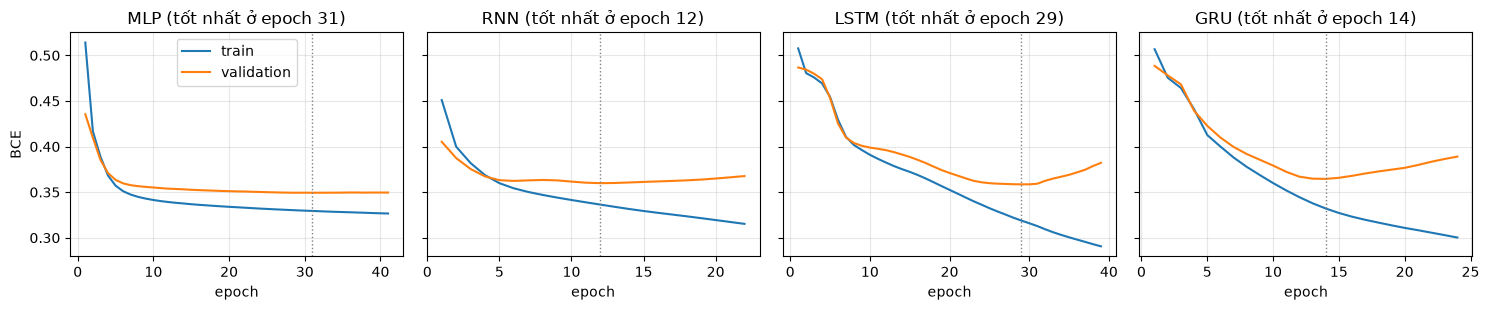

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (name, runs) in zip(axes, churn_runs.items()):
    h = runs[0]["history"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="train")
    ax.plot(ep, h["val_loss"], label="validation")
    ax.axvline(runs[0]["best_epoch"], c="gray", ls=":", lw=1)
    ax.set_title("%s (tốt nhất ở epoch %d)" % (name, runs[0]["best_epoch"]))
    ax.set_xlabel("epoch")
axes[0].set_ylabel("BCE")
axes[0].legend()
fig.tight_layout()
save(fig, "fig_keras_churn_curves.png")
plt.show()

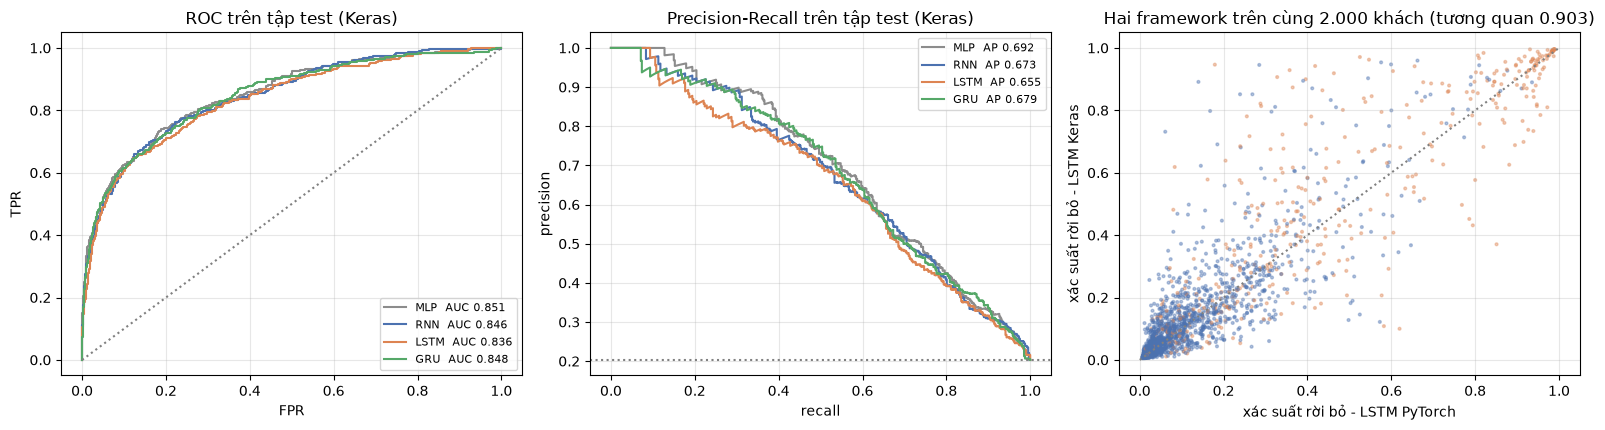

In [8]:
yt = C["y_test"]
torch_lstm_p = np.array(D.load_results("torch__churn__LSTM")["torch__churn__LSTM"]["p_test"])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for name, runs in churn_runs.items():
    p = runs[0]["p_test"]
    fpr, tpr, _ = roc_curve(yt, p)
    prec, rec, _ = precision_recall_curve(yt, p)
    axes[0].plot(fpr, tpr, c=COLORS[name], label="%s  AUC %.3f" % (name, runs[0]["metrics"]["roc_auc"]))
    axes[1].plot(rec, prec, c=COLORS[name], label="%s  AP %.3f" % (name, runs[0]["metrics"]["pr_auc"]))
axes[0].plot([0, 1], [0, 1], c="gray", ls=":")
axes[0].set_title("ROC trên tập test (Keras)")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")
axes[1].axhline(yt.mean(), c="gray", ls=":")
axes[1].set_title("Precision-Recall trên tập test (Keras)")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
k_lstm = churn_runs["LSTM"][0]["p_test"]
axes[2].scatter(torch_lstm_p, k_lstm, s=4, alpha=0.4, c=np.where(yt == 1, "#DD8452", "#4C72B0"))
axes[2].plot([0, 1], [0, 1], c="gray", ls=":")
axes[2].set_xlabel("xác suất rời bỏ - LSTM PyTorch")
axes[2].set_ylabel("xác suất rời bỏ - LSTM Keras")
axes[2].set_title("Hai framework trên cùng 2.000 khách (tương quan %.3f)"
                  % np.corrcoef(torch_lstm_p, k_lstm)[0, 1])
for ax in axes[:2]:
    ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig_keras_churn_roc_pr.png")
plt.show()

LSTM Keras, nguong 0.32:
              doan o lai  doan roi bo
that: o lai         1441          152
that: roi bo         164          243


        feature  auc_drop_keras  auc_drop_torch
  NumOfProducts          0.1369          0.1421
            Age          0.0967          0.1024
 IsActiveMember          0.0310          0.0242
        Balance          0.0236          0.0270
    Geo_Germany          0.0136          0.0202
      Geo_Spain          0.0030          0.0010
         Tenure          0.0022          0.0002
    Gender_Male          0.0020          0.0069
EstimatedSalary          0.0003          0.0006
      HasCrCard         -0.0002         -0.0011
    CreditScore         -0.0048          0.0033


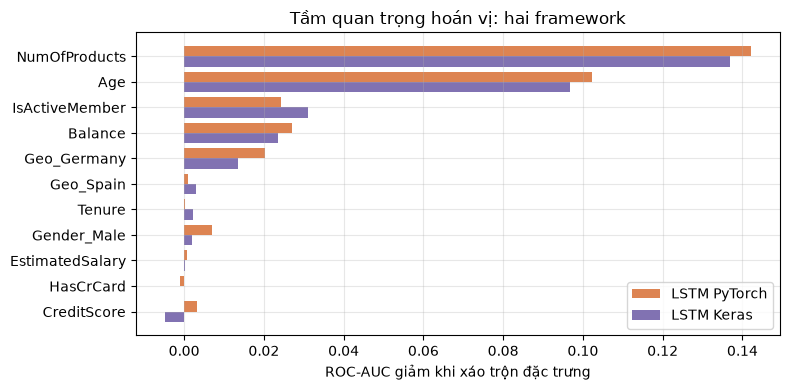

In [9]:
r0 = churn_runs["LSTM"][0]
cm = np.array(r0["metrics"]["confusion"])
print("LSTM Keras, nguong %.2f:" % r0["metrics"]["threshold"])
print(pd.DataFrame(cm, index=["that: o lai", "that: roi bo"],
                   columns=["doan o lai", "doan roi bo"]))
lstm_k = churn_models["LSTM"]
imp = D.permutation_importance(lambda X2d: sigm(predict(lstm_k, as_seq(X2d.astype("float32")))),
                               C["X_test"], C["y_test"], C["features"])
imp_torch = pd.DataFrame(D.load_results("torch__extra")["torch__extra"]["importance"])
both = imp.merge(imp_torch, on="feature", suffixes=("_keras", "_torch"))
print(both[["feature", "auc_drop_keras", "auc_drop_torch"]].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
yy = np.arange(len(both))[::-1]
ax.barh(yy + 0.2, both["auc_drop_torch"], height=0.4, color="#DD8452", label="LSTM PyTorch")
ax.barh(yy - 0.2, both["auc_drop_keras"], height=0.4, color="#8172B2", label="LSTM Keras")
ax.set_yticks(yy, both["feature"])
ax.set_xlabel("ROC-AUC giảm khi xáo trộn đặc trưng")
ax.set_title("Tầm quan trọng hoán vị: hai framework")
ax.legend()
fig.tight_layout()
save(fig, "fig_keras_churn_importance.png")
plt.show()

## 4. AMZN: dự báo lợi suất và biến động

In [10]:
mse = "mse"
HS = D.STOCK_HP["hidden"]


def stock_experiment(target):
    S = D.stock_splits(target)
    runs, models = {}, {}
    for cell in ("RNN", "LSTM", "GRU"):
        runs[cell] = []
        for seed in SEEDS:
            keras.utils.set_random_seed(seed)
            model = seq_model(cell, S["window"], len(S["features"]), HS, D.STOCK_HP["dropout"])
            info = fit(model, S, mse, D.STOCK_HP)
            pred = D.unscale(S, predict(model, S["X_test"]))
            runs[cell].append(dict(seed=seed, metrics=D.reg_metrics(S, pred), pred=pred, **info))
            if seed == SEEDS[0]:
                models[cell] = model
            print("%s %-4s seed %d: RMSE %.6f  %2d epoch  %5.1f s"
                  % (target, cell, seed, runs[cell][-1]["metrics"]["rmse"], info["epochs"],
                     info["seconds"]))
    return S, runs, models


S_ret, ret_runs, ret_models = stock_experiment("y_ret")

y_ret RNN  seed 42: RMSE 0.023895  16 epoch   19.6 s


y_ret RNN  seed 43: RMSE 0.023764  18 epoch   25.8 s


y_ret RNN  seed 44: RMSE 0.023833  11 epoch   15.9 s


y_ret LSTM seed 42: RMSE 0.023850  12 epoch   29.2 s


y_ret LSTM seed 43: RMSE 0.023821  18 epoch   44.8 s


y_ret LSTM seed 44: RMSE 0.023839  10 epoch   28.2 s


y_ret GRU  seed 42: RMSE 0.023948   9 epoch   29.8 s


y_ret GRU  seed 43: RMSE 0.023801   9 epoch   24.5 s


y_ret GRU  seed 44: RMSE 0.023877  13 epoch   35.1 s


In [11]:
RET_KEYS = ["rmse", "mae", "r2_vs_zero", "dir_acc", "price_rmse", "price_mape"]
rows = [dict(model=k, **{m: "%.5f" % v[m] for m in RET_KEYS})
        for k, v in baselines["ret"].items()]
for cell, runs in ret_runs.items():
    s = summarize(runs, RET_KEYS)
    rows.append(dict(model=cell, **{k: "%.5f ± %.5f" % s[k] for k in RET_KEYS},
                     pred_std="%.5f" % np.mean([np.std(r["pred"]) for r in runs])))
ret_table = pd.DataFrame(rows).set_index("model")
ret_table

,rmse,mae,r2_vs_zero,dir_acc,price_rmse,price_mape,pred_std
model,,,,,,,
Naive (loi suat 0),0.02376,0.01705,0.00000,nan,3.09818,1.70616,NaN
Trung binh train,0.02379,0.01706,-0.00296,0.50815,3.10553,1.70899,NaN
Ridge (cua so 60 ngay),0.02387,0.01710,-0.00926,0.50408,3.11911,1.71354,NaN
RNN,0.02383 ± 0.00005,0.01712 ± 0.00005,-0.00617 ± 0.00454,0.51902 ± 0.02244,3.11422 ± 0.00798,1.71545 ± 0.00510,0.00302
LSTM,0.02384 ± 0.00001,0.01711 ± 0.00001,-0.00667 ± 0.00102,0.50634 ± 0.00462,3.10997 ± 0.00211,1.71444 ± 0.00200,0.00122
GRU,0.02388 ± 0.00006,0.01714 ± 0.00006,-0.00994 ± 0.00507,0.50498 ± 0.01186,3.11335 ± 0.00843,1.71708 ± 0.00679,0.00149


In [12]:
S_vol, vol_runs, vol_models = stock_experiment("y_vol")

y_vol RNN  seed 42: RMSE 0.009808  26 epoch   34.7 s


y_vol RNN  seed 43: RMSE 0.009739  19 epoch   24.4 s


y_vol RNN  seed 44: RMSE 0.010030  21 epoch   27.0 s


y_vol LSTM seed 42: RMSE 0.009690  11 epoch   29.8 s


y_vol LSTM seed 43: RMSE 0.009631  11 epoch   29.2 s


y_vol LSTM seed 44: RMSE 0.009516  13 epoch   34.2 s


y_vol GRU  seed 42: RMSE 0.009755  21 epoch   61.6 s


y_vol GRU  seed 43: RMSE 0.009802  32 epoch   96.3 s


y_vol GRU  seed 44: RMSE 0.009805  25 epoch   79.3 s


In [13]:
VOL_KEYS = ["rmse", "mae", "r2", "corr"]
rows = [dict(model=k, **{m: "%.5f" % v[m] for m in VOL_KEYS})
        for k, v in baselines["vol"].items()]
for cell, runs in vol_runs.items():
    s = summarize(runs, VOL_KEYS)
    rows.append(dict(model=cell, **{k: "%.5f ± %.5f" % s[k] for k in VOL_KEYS},
                     epochs="%.0f" % np.mean([r["epochs"] for r in runs]),
                     seconds="%.1f" % np.mean([r["seconds"] for r in runs])))
vol_table = pd.DataFrame(rows).set_index("model")
vol_table

,rmse,mae,r2,corr,epochs,seconds
model,,,,,,
Bien dong 20 ngay qua,0.01148,0.00834,-0.02187,0.37504,NaN,NaN
Trung binh train,0.01397,0.01221,-0.51349,0.00000,NaN,NaN
Ridge (cua so 60 ngay),0.00968,0.00663,0.27316,0.52932,NaN,NaN
RNN,0.00986 ± 0.00012,0.00677 ± 0.00006,0.24568 ± 0.01904,0.50078 ± 0.01694,22,28.7
LSTM,0.00961 ± 0.00007,0.00649 ± 0.00004,0.28304 ± 0.01081,0.53736 ± 0.00705,12,31.1
GRU,0.00979 ± 0.00002,0.00665 ± 0.00011,0.25669 ± 0.00345,0.51561 ± 0.00697,26,79.1


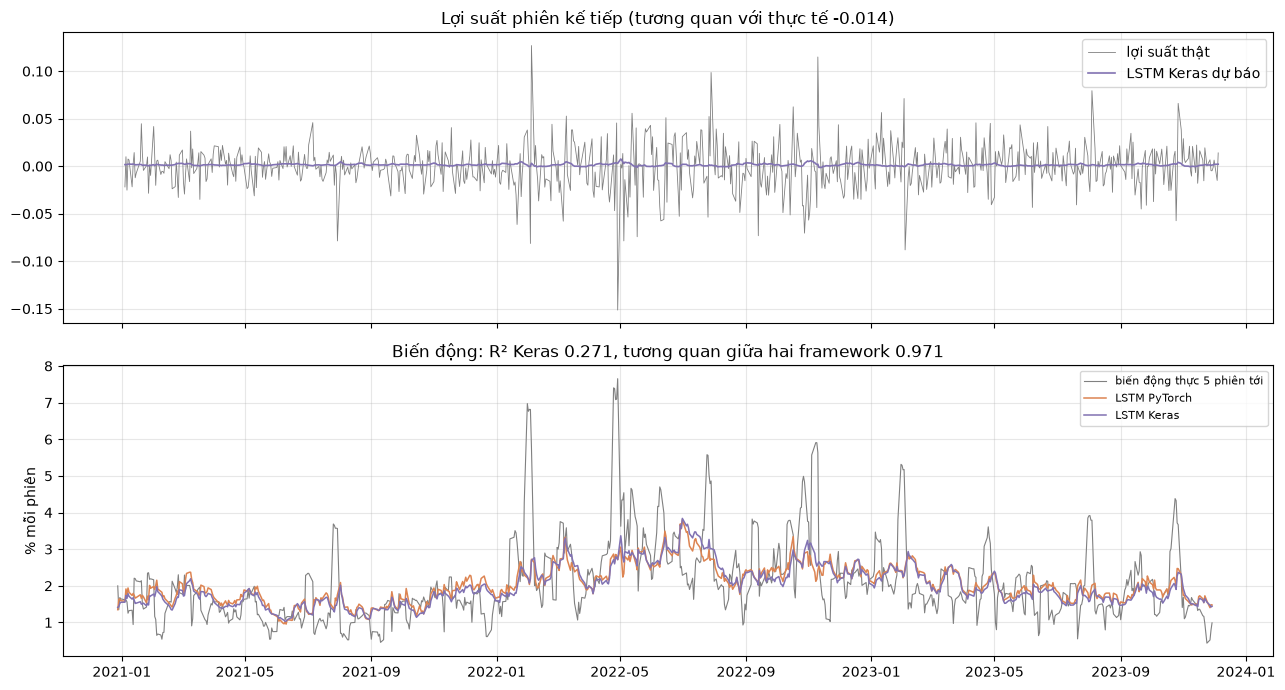

In [14]:
torch_vol = np.array(D.load_results("torch__vol__LSTM")["torch__vol__LSTM"]["pred"])
k_ret, k_vol = ret_runs["LSTM"][0], vol_runs["LSTM"][0]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
a1.plot(S_ret["date_test"], S_ret["yraw_test"], c="gray", lw=0.6, label="lợi suất thật")
a1.plot(S_ret["date_test"], k_ret["pred"], c="#8172B2", lw=1.2, label="LSTM Keras dự báo")
a1.set_title("Lợi suất phiên kế tiếp (tương quan với thực tế %.3f)" % k_ret["metrics"]["corr"])
a1.legend()
a2.plot(S_vol["date_test"], S_vol["yraw_test"] * 100, c="gray", lw=0.8, label="biến động thực 5 phiên tới")
a2.plot(S_vol["date_test"], torch_vol * 100, c="#DD8452", lw=1.1, label="LSTM PyTorch")
a2.plot(S_vol["date_test"], k_vol["pred"] * 100, c="#8172B2", lw=1.1, label="LSTM Keras")
a2.set_ylabel("% mỗi phiên")
a2.set_title("Biến động: R² Keras %.3f, tương quan giữa hai framework %.3f"
             % (k_vol["metrics"]["r2"], np.corrcoef(torch_vol, k_vol["pred"])[0, 1]))
a2.legend(fontsize=8)
fig.tight_layout()
save(fig, "fig_keras_stock_test.png")
plt.show()

## 5. Dự báo phiên kế tiếp sau ngày cuối của dữ liệu

In [15]:
common = np.intersect1d(S_ret["date_test"], S_vol["date_test"])
ir, iv = np.isin(S_ret["date_test"], common), np.isin(S_vol["date_test"], common)
r_true = S_ret["yraw_test"][ir]
lo = k_ret["pred"][ir] - 1.96 * k_vol["pred"][iv]
hi = k_ret["pred"][ir] + 1.96 * k_vol["pred"][iv]
coverage = float(np.mean((r_true >= lo) & (r_true <= hi)))

x_last, last_date, last_close = D.last_window(S_ret)
r_hat = float(D.unscale(S_ret, predict(ret_models["LSTM"], x_last))[0])
s_hat = float(D.unscale(S_vol, predict(vol_models["LSTM"], x_last))[0])
forecast = dict(last_date=str(last_date.date()), last_close=last_close, r_hat=r_hat,
                sigma_hat=s_hat, price_hat=last_close * np.exp(r_hat),
                price_lo=last_close * np.exp(r_hat - 1.96 * s_hat),
                price_hi=last_close * np.exp(r_hat + 1.96 * s_hat), coverage_test=coverage)
print({k: (round(v, 5) if isinstance(v, float) else v) for k, v in forecast.items()})

{'last_date': '2023-12-05', 'last_close': 146.88001, 'r_hat': 0.00132, 'sigma_hat': 0.01503, 'price_hat': np.float64(147.07336), 'price_lo': np.float64(142.80264), 'price_hi': np.float64(151.4718), 'coverage_test': 0.93033}


## 6. Ghi kết quả

In [16]:
def pack(runs, keys, extra):
    return dict(runs=[{k: v for k, v in r.items() if k not in ("p_test", "pred", "history")}
                      for r in runs],
                summary={k: list(v) for k, v in summarize(runs, keys).items()},
                history=runs[0]["history"], **extra)


for name, runs in churn_runs.items():
    D.save_result("keras__churn__" + name,
                  pack(runs, KEYS, dict(framework="Keras", task="churn", model=name,
                                        params=churn_models[name].count_params(),
                                        p_test=runs[0]["p_test"])))
for cell, runs in ret_runs.items():
    D.save_result("keras__ret__" + cell,
                  pack(runs, RET_KEYS, dict(framework="Keras", task="ret", model=cell,
                                            params=ret_models[cell].count_params(),
                                            pred=runs[0]["pred"])))
for cell, runs in vol_runs.items():
    D.save_result("keras__vol__" + cell,
                  pack(runs, VOL_KEYS, dict(framework="Keras", task="vol", model=cell,
                                            params=vol_models[cell].count_params(),
                                            pred=runs[0]["pred"])))
D.save_result("keras__extra", dict(importance=imp.to_dict("records"), forecast=forecast))
print(sorted(p.name for p in D.RESULTS.glob("keras__*.json")))

['keras__churn__GRU.json', 'keras__churn__LSTM.json', 'keras__churn__MLP.json', 'keras__churn__RNN.json', 'keras__extra.json', 'keras__ret__GRU.json', 'keras__ret__LSTM.json', 'keras__ret__RNN.json', 'keras__vol__GRU.json', 'keras__vol__LSTM.json', 'keras__vol__RNN.json']
